# GBHeat | Custom scenario alignment and benchmark comparison

**Purpose:** Create and save a user-defined housing/technology scenario, generate its half-hourly thermal heat demand using the **RHPP/Watson method in the supplied custom-scenario module**, and reproduce the **original `Validation_3.ipynb` benchmark plots** (12 × 6 inches, same line widths, linestyle, ticks, legend and grid).

**Execution:** run from top to bottom after cloning GBHeat, installing its Python package and obtaining the external precomputed heating-pattern data. All results go to `data/outputs/`; no model inputs are modified.

**Source fidelity:** The uploaded `half_hourly_profile_costumed_scenario.py` uses RHPP fractions **daytime 0.28, bi-modal 0.08, continuous 0.64**, and an insulation multiplier. Its active function uses undefined globals (`FES_data`, `total_dwelling_new`) and obsolete paths, so this notebook makes those inputs explicit, while preserving the RHPP weighting and multiplication. It **does not silently call the broken function**. Technology-share alignment uses the current `gbheatmodel.align_with_other_future_scenario` functions. The resulting RHPP profile is a **total thermal heat profile per grid**, not a technology-resolved profile. 

**Peak definition:** the plotted peak day follows the supplied validation notebook: it is the day with the largest **daily energy total**, not necessarily the date of the highest half-hourly load.

## 1. Scenario configuration — edit only this cell

In [1]:
from pathlib import Path

WEATHER_YEAR = 2010
FUTURE_YEAR = 2050
SCENARIO_NAME = "Watson_custom"
TOTAL_DWELLINGS = 25_800_000
INSULATION_IMPROVEMENT = 1.0  # Multiplicative heat factor; 1 = no change

# Technology stock alignment, as in GBHeat scenario-alignment functions
TECHNOLOGIES = ["ASHP", "GSHP"]
TECH_SHARES = [0.75, 0.25]

# RHPP base-case patterns in the uploaded module
RHPP_SHARES = {"daytime": 0.28, "bi-modal": 0.08, "continuous": 0.64}

# The current GBHeat source input; do not overwrite this CSV
SCENARIO_INPUT_REL = "data/Scenario_Alignment/heat_techs_distribution_grid_square.csv"
PATTERN_REL = f"data/heat_demand_profiles_patterns/HD_heat_patterns_{WEATHER_YEAR}"

# Comparison with already generated standard FES scenarios (optional)
FES_YEAR = "2022"
COMPARE_FES_SCENARIOS = ["LW"] # e.g. ["LW", "CT", "ST", "FS"] or []

# Paths can be absolute or relative to repository; leave None to discover
WATSON_BENCHMARK_CSV = None
SANSOM_BENCHMARK_CSV = None
SAVE_FIGURES = True
SHOW_FIGURES = True
OVERWRITE_CUSTOM_PROFILES = False

## 2. Discover repository and validate scenario settings

In [2]:
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from gbheatmodel.align_with_other_future_scenario import scale_FES_dwellings, assign_tech_shares


def discover_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "data").is_dir() and (p / "src").is_dir():
            return p
    raise FileNotFoundError("Run Jupyter inside the GBHeatModel repository (or set PROJECT_ROOT manually).")

PROJECT_ROOT = discover_root()
DATA_DIR = PROJECT_ROOT / "data"
OUTPUT_ROOT = DATA_DIR / "outputs"

def resolve_repo_file(path):
    path = Path(path)
    return path if path.is_absolute() else PROJECT_ROOT / path

if not re.fullmatch(r"[A-Za-z0-9_-]+", SCENARIO_NAME):
    raise ValueError("Use only letters, digits, hyphens and underscores in SCENARIO_NAME.")
if not 0 < INSULATION_IMPROVEMENT <= 1.5:
    raise ValueError("INSULATION_IMPROVEMENT must be > 0 and <= 1.5.")
if TOTAL_DWELLINGS <= 0:
    raise ValueError("TOTAL_DWELLINGS must be positive.")
if len(TECHNOLOGIES) != len(TECH_SHARES) or len(set(TECHNOLOGIES)) != len(TECHNOLOGIES):
    raise ValueError("Technology names and shares must be paired uniquely.")
if not np.isclose(sum(TECH_SHARES), 1.0, atol=1e-9) or any(s < 0 for s in TECH_SHARES):
    raise ValueError("TECH_SHARES must be nonnegative and add to one.")
if not np.isclose(sum(RHPP_SHARES.values()), 1, atol=1e-9):
    raise ValueError("RHPP pattern fractions must sum to one.")

INPUT_CSV = resolve_repo_file(SCENARIO_INPUT_REL)
PATTERN_DIR = resolve_repo_file(PATTERN_REL)
RUN_ID = f"{WEATHER_YEAR}_{SCENARIO_NAME}_{FUTURE_YEAR}"
OUT_DIR = OUTPUT_ROOT / "heating_profiles" / "heating_profiles_custom" / RUN_ID
ALIGN_DIR = OUTPUT_ROOT / "Scenario_Alignment_Outputs" / RUN_ID
FIGURE_DIR = OUTPUT_ROOT / "figures" / RUN_ID / "06_Custom_Scenario"
for p in [OUT_DIR, ALIGN_DIR, FIGURE_DIR]:
    p.mkdir(parents=True, exist_ok=True)
if not INPUT_CSV.is_file():
    raise FileNotFoundError(f"Scenario input missing: {INPUT_CSV}")
if not PATTERN_DIR.is_dir():
    raise FileNotFoundError(f"Pattern directory missing: {PATTERN_DIR}. Download the external GBHeat pattern dataset first.")
print("Project root:", PROJECT_ROOT)
print("Input:", INPUT_CSV)
print("Patterns:", PATTERN_DIR)
print("Custom output:", OUT_DIR)
print("Figures:", FIGURE_DIR)

Project root: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel
Input: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\Scenario_Alignment\heat_techs_distribution_grid_square.csv
Patterns: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\heat_demand_profiles_patterns\HD_heat_patterns_2010
Custom output: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\heating_profiles_custom\2010_Watson_custom_2050
Figures: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\figures\2010_Watson_custom_2050\06_Custom_Scenario


## 3. Build and save custom technology-stock allocation

These are the existing GBHeat scenario-alignment functions. The original source CSV remains unchanged. This stock table can be used in further scenario experiments. The RHPP comparison later uses its **total dwellings per grid**, as in the supplied module; technology shares do not affect RHPP thermal demand directly.

In [3]:
# Read the original grid-stock data and preserve the dwelling totals BEFORE technology allocation.
FES_data = pd.read_csv(INPUT_CSV)


def normalise_grid_id(frame, label):
    """Accept Grid_ID as a column or as the DataFrame index."""
    if not isinstance(frame, pd.DataFrame):
        raise TypeError(f"{label} returned {type(frame).__name__}, expected a DataFrame")
    result = frame.copy()
    if "Grid_ID" not in result.columns:
        if result.index.name == "Grid_ID":
            result = result.reset_index()
        else:
            raise ValueError(
                f"{label} has neither a Grid_ID column nor a Grid_ID index. "
                f"Columns: {result.columns.tolist()}; index name: {result.index.name!r}"
            )
    result["Grid_ID"] = result["Grid_ID"].astype(str).str.strip()
    if result["Grid_ID"].isna().any() or result["Grid_ID"].eq("").any():
        raise ValueError(f"{label}: empty Grid_ID")
    if result["Grid_ID"].duplicated().any():
        raise ValueError(f"{label}: duplicate Grid_ID values")
    return result


FES_data = normalise_grid_id(FES_data, "Original FES stock input")
scaled_dwellings = normalise_grid_id(
    scale_FES_dwellings(FES_data.copy(), TOTAL_DWELLINGS),
    "scale_FES_dwellings",
)
custom_stocks = normalise_grid_id(
    assign_tech_shares(scaled_dwellings.copy(), TECHNOLOGIES, TECH_SHARES),
    "assign_tech_shares",
)

print("Scaled-stock columns:", scaled_dwellings.columns.tolist())
print("Custom-stock columns:", custom_stocks.columns.tolist())

# Some GBHeat alignment functions retain only Grid_ID and the selected technology
# columns; they do not carry a total_dwellings column through to the result.
# Recover total dwellings from the scaled stock table, NOT from an unrelated
# original FES technology mix or an assumed per-grid uniform distribution.
POSSIBLE_TOTAL_COLUMNS = ["total_dwellings", "Total_Dwellings", "Total dwellings"]
scaled_total_col = next((c for c in POSSIBLE_TOTAL_COLUMNS if c in scaled_dwellings.columns), None)
if scaled_total_col is None:
    # Only infer a total from explicitly identified stock columns when the
    # scaled table has no total column. Never sum arbitrary numeric columns:
    # these may contain coordinates, shares, or other metadata.
    original_tech_cols = [c for c in FES_data.columns if c not in {"Grid_ID"}]
    original_tech_cols = [c for c in original_tech_cols
                          if c in scaled_dwellings.columns
                          and pd.api.types.is_numeric_dtype(FES_data[c])
                          and pd.api.types.is_numeric_dtype(scaled_dwellings[c])]
    if not original_tech_cols:
        raise ValueError(
            "Cannot identify dwelling stock columns in scale_FES_dwellings output. "
            f"Columns: {scaled_dwellings.columns.tolist()}. "
            "Please show the printed columns and the function source."
        )
    print("No total_dwellings column; using these matching input stock columns:", original_tech_cols)
    grid_totals = scaled_dwellings[original_tech_cols].sum(axis=1)
else:
    grid_totals = pd.to_numeric(scaled_dwellings[scaled_total_col], errors="raise")

scaled_totals = scaled_dwellings[["Grid_ID"]].copy()
scaled_totals["total_dwellings"] = grid_totals.to_numpy(dtype=float)
if not np.isfinite(scaled_totals["total_dwellings"]).all() or (scaled_totals["total_dwellings"] < 0).any():
    raise ValueError("Invalid dwelling totals in scaled stock table")

# Never overwrite a provided total unless it matches the independently scaled
# stock totals. Join on Grid_ID, not on DataFrame row order.
if "total_dwellings" in custom_stocks.columns:
    existing = pd.to_numeric(custom_stocks["total_dwellings"], errors="raise")
    checked = custom_stocks[["Grid_ID"]].merge(
        scaled_totals, on="Grid_ID", how="left", validate="one_to_one"
    )
    if checked["total_dwellings"].isna().any() or not np.allclose(
        existing.to_numpy(dtype=float), checked["total_dwellings"].to_numpy(dtype=float),
        rtol=1e-6, atol=1e-4,
    ):
        raise ValueError("Returned total_dwellings does not match scaled dwelling stock")
else:
    custom_stocks = custom_stocks.merge(
        scaled_totals, on="Grid_ID", how="left", validate="one_to_one"
    )

if len(custom_stocks) != len(scaled_totals) or custom_stocks["total_dwellings"].isna().any():
    raise ValueError("Technology assignment omitted grid squares or introduced unknown Grid_IDs")

for tech in TECHNOLOGIES:
    if tech not in custom_stocks.columns:
        raise ValueError(f"Technology column not created: {tech}; available: {custom_stocks.columns.tolist()}")
    custom_stocks[tech] = pd.to_numeric(custom_stocks[tech], errors="raise")
    if not np.isfinite(custom_stocks[tech]).all() or (custom_stocks[tech] < 0).any():
        raise ValueError(f"Invalid technology stock counts: {tech}")

if not np.allclose(
    custom_stocks[TECHNOLOGIES].sum(axis=1).to_numpy(dtype=float),
    custom_stocks["total_dwellings"].to_numpy(dtype=float),
    rtol=1e-6, atol=1e-4,
):
    raise ValueError("Allocated technology dwellings do not sum to per-grid dwelling totals")
if not np.isclose(custom_stocks["total_dwellings"].sum(), TOTAL_DWELLINGS, rtol=1e-5):
    raise ValueError("Scaled dwelling count does not match TOTAL_DWELLINGS")

scaled_path = ALIGN_DIR / "scaled_dwellings.csv"
stock_path = ALIGN_DIR / "custom_technology_stocks.csv"
scaled_dwellings.to_csv(scaled_path, index=False)
custom_stocks.to_csv(stock_path, index=False)
print("Saved stock alignment:", stock_path)
print("Total dwellings:", custom_stocks["total_dwellings"].sum())
print("Technology totals:")
display(custom_stocks[TECHNOLOGIES].sum().to_frame("Dwellings"))


Scaled-stock columns: ['Grid_ID', 'total_dwellings']
Custom-stock columns: ['Grid_ID', 'ASHP', 'GSHP']
Saved stock alignment: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\Scenario_Alignment_Outputs\2010_Watson_custom_2050\custom_technology_stocks.csv
Total dwellings: 25800000.0
Technology totals:


,Dwellings
ASHP,19350000.0
GSHP,6450000.0


## 4. Generate and save RHPP half-hourly demand

Reproduces the active method in `half_hourly_profile_costumed_scenario.py`: RHPP pattern-weighted heat × dwellings × insulation factor. Uses the current project paths and validates all grid files, timestamps and half-hour counts. A non-leap weather year and non-leap target year are currently required for the original 17,520-interval method.

In [4]:
import calendar
if calendar.isleap(WEATHER_YEAR) or calendar.isleap(FUTURE_YEAR):
    raise ValueError("The supplied RHPP module assumes 17,520 half-hours; use non-leap years until leap-year mapping is implemented.")

all_grids = custom_stocks.set_index("Grid_ID")
PATTERN_COLUMNS = list(RHPP_SHARES)
expected_index = pd.date_range(f"{FUTURE_YEAR}-01-01", periods=17520, freq="30min")
created_files = []
expected_files = []
missing_pattern_grids = []
for grid_id, row in all_grids.iterrows():
    pattern_file = PATTERN_DIR / f"({grid_id})_{WEATHER_YEAR}.csv"
    result_file = OUT_DIR / f"half_hourly_HD_{grid_id}_{SCENARIO_NAME}_{WEATHER_YEAR}_{FUTURE_YEAR}.csv"
    expected_files.append(result_file)
    if not pattern_file.is_file():
        missing_pattern_grids.append(grid_id)
        continue
    if result_file.exists() and not OVERWRITE_CUSTOM_PROFILES:
        continue
    pattern = pd.read_csv(pattern_file, index_col=0)
    if len(pattern) != 17520 or not set(PATTERN_COLUMNS).issubset(pattern.columns):
        raise ValueError(f"Incorrect pattern shape/columns: {pattern_file}")
    vals = pattern[PATTERN_COLUMNS].apply(pd.to_numeric, errors="raise")
    if not np.isfinite(vals.to_numpy()).all():
        raise ValueError(f"Missing or invalid pattern values: {pattern_file}")
    hh = sum(vals[k].to_numpy() * w for k, w in RHPP_SHARES.items())
    hh = hh * float(row["total_dwellings"]) * INSULATION_IMPROVEMENT
    if not np.isfinite(hh).all() or (hh < 0).any():
        raise ValueError(f"Invalid heat demand for grid {grid_id}")
    pd.DataFrame({"heat_demand": hh}, index=expected_index).to_csv(result_file)
    created_files.append(result_file)

if missing_pattern_grids:
    raise FileNotFoundError(f"Missing {len(missing_pattern_grids)} pattern files; first IDs: {missing_pattern_grids[:10]}")
missing_outputs = [p for p in expected_files if not p.is_file()]
if missing_outputs:
    raise RuntimeError(f"Output incomplete: {len(missing_outputs)} grid results are missing.")
print(f"Grid profiles: {len(expected_files)}, created/overwritten: {len(created_files)}")
print("Profiles saved to:", OUT_DIR)

Grid profiles: 738, created/overwritten: 738
Profiles saved to: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\heating_profiles\heating_profiles_custom\2010_Watson_custom_2050


## 5. Save a reproducibility manifest

In [5]:
manifest = {
    "weather_year": WEATHER_YEAR,
    "future_year": FUTURE_YEAR,
    "scenario_name": SCENARIO_NAME,
    "source_stocks": str(INPUT_CSV.relative_to(PROJECT_ROOT)),
    "pattern_directory": str(PATTERN_DIR.relative_to(PROJECT_ROOT)),
    "total_dwellings_requested": TOTAL_DWELLINGS,
    "total_dwellings_allocated": float(custom_stocks["total_dwellings"].sum()),
    "technology_shares": dict(zip(TECHNOLOGIES, TECH_SHARES)),
    "rhpp_pattern_shares": RHPP_SHARES,
    "insulation_improvement_factor": INSULATION_IMPROVEMENT,
    "grid_count": len(expected_files),
    "output_unit": "kWh per half-hour (assumed by source pattern profiles)",
    "peak_day_selection": "maximum national daily total (kWh)",
    "custom_output_dir": str(OUT_DIR.relative_to(PROJECT_ROOT)),
}
manifest_path = ALIGN_DIR / "scenario_manifest.json"
manifest_path.write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Saved manifest:", manifest_path)

Saved manifest: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\data\outputs\Scenario_Alignment_Outputs\2010_Watson_custom_2050\scenario_manifest.json


## 6. Aggregate saved grid profiles to national demand

Loads the saved profiles (not an independent model calculation). The original validation notebook accepts any CSV; here we restrict filenames to this exact custom scenario, so diagnostics and unrelated CSVs cannot accidentally enter the national sum.

In [6]:
def national_half_hourly_heat_from_folder(folder, pattern="half_hourly_HD_*.csv"):
    files = sorted(Path(folder).glob(pattern))
    if not files:
        raise FileNotFoundError(f"No heat profiles found in {folder} (pattern: {pattern})")
    national = None
    index_reference = None
    for path in files:
        df = pd.read_csv(path, index_col=0, parse_dates=True)
        if df.empty or not isinstance(df.index, pd.DatetimeIndex) or df.index.has_duplicates:
            raise ValueError(f"Invalid half-hourly profile {path.name}")
        if index_reference is None:
            index_reference = df.index
        elif not index_reference.equals(df.index):
            raise ValueError(f"Misaligned timestamps in {path.name}")
        values = df.apply(pd.to_numeric, errors="raise")
        if not np.isfinite(values.to_numpy()).all():
            raise ValueError(f"Invalid data in {path.name}")
        s = values.sum(axis=1)
        national = s if national is None else national.add(s, fill_value=0)
    return national.sort_index()

custom_national = national_half_hourly_heat_from_folder(OUT_DIR,
    f"half_hourly_HD_*_{SCENARIO_NAME}_{WEATHER_YEAR}_{FUTURE_YEAR}.csv")
custom_national.to_frame("thermal_heat_kWh_per_halfhour").to_csv(ALIGN_DIR / "national_half_hourly_heat.csv")
print(f"Annual custom heat demand: {custom_national.sum()/1e9:.3f} TWh")
print(f"Custom coincident peak: {custom_national.max()*2/1e6:.3f} GW")

Annual custom heat demand: 445.048 TWh
Custom coincident peak: 172.808 GW


## 7. Load optional Watson and Sansom benchmark profiles

Benchmarks are **digitised GW load profiles** and are only read if supplied. The notebook does not fabricate benchmark values. Set the CSV paths in Section 1 or place files in `data/validation/` or `Analysis/data/Validation/`.

In [7]:
def locate_benchmark(filename, explicit_path):
    choices = ([resolve_repo_file(explicit_path)] if explicit_path else []) + [
        DATA_DIR / "validation" / filename,
        DATA_DIR / "Validation" / filename,
        PROJECT_ROOT / "Analysis" / "data" / "Validation" / filename,
    ]
    return next((p for p in choices if p.is_file()), None)


def load_clean_profile(path):
    df = pd.read_csv(path, header=None)
    if df.shape[1] != 2:
        raise ValueError(f"Expected 2 columns in {path}")
    df.columns = ["time_hours", "GW"]
    df["time_hours"] = pd.to_numeric(df["time_hours"], errors="coerce")
    df["GW"] = pd.to_numeric(df["GW"], errors="coerce")
    df = df.dropna().drop_duplicates(subset="time_hours").sort_values("time_hours")
    if len(df) < 2:
        raise ValueError(f"Insufficient benchmark points: {path}")
    return pd.Series(np.interp(np.arange(0, 24, .5), df["time_hours"], df["GW"]),
                     index=np.arange(0, 24, .5))

watson_path = locate_benchmark("Watson_HD.csv", WATSON_BENCHMARK_CSV)
sansom_path = locate_benchmark("Sansom_HD.csv", SANSOM_BENCHMARK_CSV)
watson_halfhour = load_clean_profile(watson_path) if watson_path else None
sansom_halfhour = load_clean_profile(sansom_path) if sansom_path else None
print("Watson:", watson_path or "not supplied")
print("Sansom:", sansom_path or "not supplied")

Watson: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\Analysis\data\Validation\Watson_HD.csv
Sansom: C:\Users\s2583817\OneDrive - University of Edinburgh\Documents\Projects\PhD_Project\Python\GBHeatModel\Analysis\data\Validation\Sansom_HD.csv


## 8. Plot — custom scenario vs benchmarks

**Style retained from the original `Validation_3.ipynb`:** 12 × 6 inches, half-hour x axis, 2-point model lines, 3-point dashed Watson and dash-dot Sansom, original grid/legend style. The output is saved at 600 dpi in `data/outputs/figures/`.

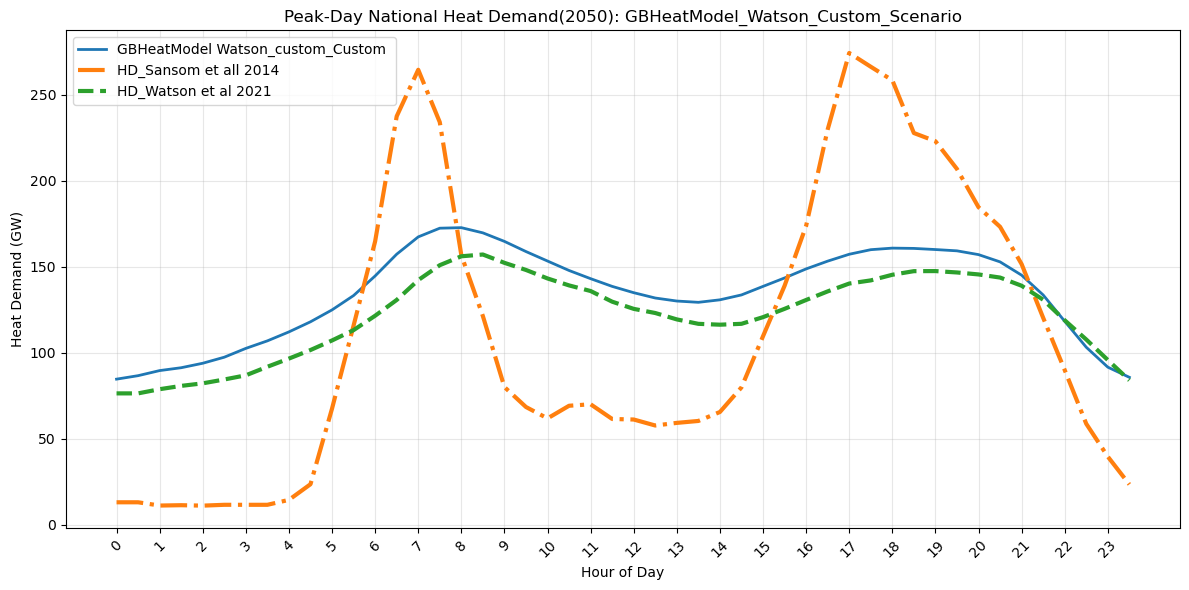

Peak energy day: 2050-12-20; daily maximum: 172.808 GW


In [8]:
# Original Validation_3 plotting layout and line styles are intentionally preserved.
time_axis = [round(i * 0.5, 1) for i in range(48)]
daily = custom_national.resample("D").sum()
peak_day = daily.idxmax()
day_series = custom_national.loc[custom_national.index.date == peak_day.date()]
if len(day_series) != 48:
    raise ValueError(f"Peak day has {len(day_series)} points, expected 48")
day_gw = day_series.to_numpy() / (1e6 * 0.5)

fig = plt.figure(figsize=(12, 6))
plt.plot(time_axis, day_gw, label=f"GBHeatModel {SCENARIO_NAME}_Custom ", linewidth=2)
if sansom_halfhour is not None:
    plt.plot(time_axis, sansom_halfhour.values, label="HD_Sansom et all 2014", linewidth=3, linestyle="-.")
if watson_halfhour is not None:
    plt.plot(time_axis, watson_halfhour.values, label="HD_Watson et al 2021", linewidth=3, linestyle="--")
plt.xlabel("Hour of Day")
plt.ylabel("Heat Demand (GW)")
plt.title(f"Peak-Day National Heat Demand({FUTURE_YEAR}): GBHeatModel_Watson_Custom_Scenario")
plt.xticks(time_axis[::2], rotation=45)
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / f"custom_vs_benchmarks_{RUN_ID}.png", dpi=600, bbox_inches="tight")
if SHOW_FIGURES: plt.show()
else: plt.close(fig)
print(f"Peak energy day: {peak_day.date()}; daily maximum: {day_gw.max():.3f} GW")

## 9. Plot — standard FES scenarios vs Watson/Sansom and custom scenario

Uses the first comparison plot layout from the supplied validation notebook. Missing standard scenario folders are omitted and reported. **Each model scenario is shown on its own peak-energy day**, as in the source notebook; the plotted dates may differ.

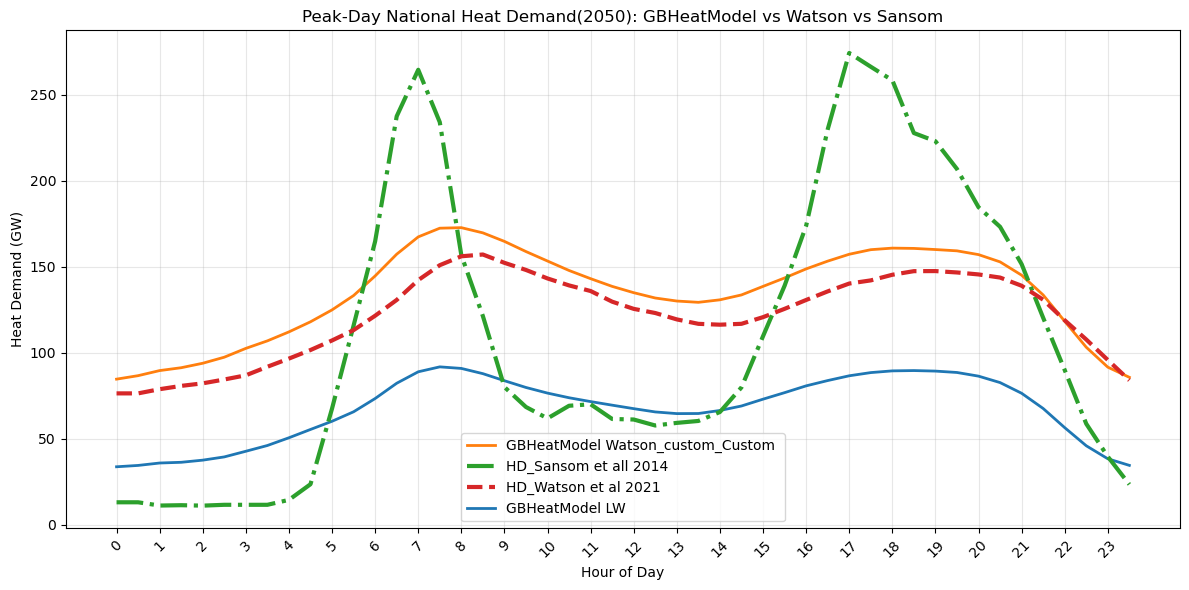

,date,peak_gw
LW,2050-12-20,91.882624
Watson_custom_Custom,2050-12-20,172.808190


In [9]:
fes_folders = {
    scen: OUTPUT_ROOT / "heating_profiles" / f"{WEATHER_YEAR}_{FES_YEAR}_{scen}_{FUTURE_YEAR}"
    for scen in COMPARE_FES_SCENARIOS
}
scenario_series = {}
for scen, folder in fes_folders.items():
    if not folder.is_dir():
        print(f"Skipping {scen}: folder missing: {folder}")
        continue
    try:
        scenario_series[scen] = national_half_hourly_heat_from_folder(folder, "half_hourly_heat_profile_*.csv")
    except Exception as e:
        print(f"Skipping {scen}: {e}")

fig = plt.figure(figsize=(12, 6))
peak_info = {}
for scen, hh in {**scenario_series, f"{SCENARIO_NAME}_Custom": custom_national}.items():
    daily = hh.resample("D").sum()
    peak_day = daily.idxmax()
    day_series = hh[hh.index.date == peak_day.date()]
    if len(day_series) != 48:
        print(f"Skipping {scen}: peak day has {len(day_series)} steps")
        continue
    day_gw = day_series.to_numpy() / (1e6 * 0.5)
    peak_info[scen] = {"date": str(peak_day.date()), "peak_gw": float(day_gw.max())}
    plt.plot(time_axis, day_gw, label=f"GBHeatModel {scen} ", linewidth=2)
if sansom_halfhour is not None:
    plt.plot(time_axis, sansom_halfhour.values, label="HD_Sansom et all 2014", linewidth=3, linestyle="-.")
if watson_halfhour is not None:
    plt.plot(time_axis, watson_halfhour.values, label="HD_Watson et al 2021", linewidth=3, linestyle="--")
plt.xlabel("Hour of Day")
plt.ylabel("Heat Demand (GW)")
plt.title(f"Peak-Day National Heat Demand({FUTURE_YEAR}): GBHeatModel vs Watson vs Sansom")
plt.xticks(time_axis[::2], rotation=45)
plt.grid(True, alpha=0.3)
handles, labels = plt.gca().get_legend_handles_labels()
bench = [i for i, label in enumerate(labels) if ("Sansom" in label or "Watson" in label)]
others = [i for i in range(len(labels)) if i not in bench]
order = bench + others
plt.legend([handles[i] for i in order], [labels[i] for i in order])
plt.tight_layout()
if SAVE_FIGURES:
    fig.savefig(FIGURE_DIR / f"all_scenarios_vs_benchmarks_{RUN_ID}.png", dpi=600, bbox_inches="tight")
if SHOW_FIGURES: plt.show()
else: plt.close(fig)
pd.DataFrame.from_dict(peak_info, orient="index").to_csv(ALIGN_DIR / "peak_day_comparison.csv")
display(pd.DataFrame.from_dict(peak_info, orient="index"))

## Results and methodological notes

Outputs are saved **only** under `data/outputs/`, which should remain Git-ignored.

- `Scenario_Alignment_Outputs/<run_id>/`: scaled stocks, allocated technology stocks, manifest, national half-hourly heat and peak summaries.
- `heating_profiles/heating_profiles_custom/<run_id>/`: half-hourly thermal heat demand for each grid square.
- `figures/<run_id>/06_Custom_Scenario/`: original-style PNG benchmark comparisons.

**Limitations:** This notebook reproduces the RHPP/Watson *total-heat* method, not the full technology-specific GBHeat model. Its custom technology shares are saved for scenario alignment, but the RHPP total heat profile depends on the **total dwelling stock**, weather-pattern inputs and insulation factor. The source custom module's other, technology-specific implementation is commented out; implementing it as a separate interface should be done only after verifying the active package's technology profile schema. Any benchmark comparison requires the actual benchmark CSVs. The user remains responsible for ensuring dataset units and model years are compatible.